# pix2pix (Isola et al., 2017) as example

*Image-to-Image Translation with Conditional Adversarial Networks*, CVPR 2017 —
[arXiv:1611.07004](https://arxiv.org/abs/1611.07004).

The two networks as in the authors' official PyTorch implementation
([junyanz/pytorch-CycleGAN-and-pix2pix](https://github.com/junyanz/pytorch-CycleGAN-and-pix2pix),
`models/networks.py`, BSD licence), with the pix2pix defaults for 256×256 images:

- **Generator — U-Net 256** (`--netG unet_256`): 8 down-sampling steps (Conv 4×4, stride 2,
  LeakyReLU 0.2, BatchNorm; none on the first layer) to a 1×1 bottleneck, then 8 up-sampling
  steps (ConvTranspose 4×4, ReLU, BatchNorm, dropout 0.5 in three of the 512-channel steps).
  Skip connections concatenate each encoder output with its mirrored decoder input; Tanh output.
  Channels: C64-C128-C256-C512-C512-C512-C512-C512 down, the mirror image up.
- **Discriminator — 70×70 PatchGAN** (`--netD basic`, 3 layers): it sees the input image and
  the real or generated output, concatenated (6 channels), and classifies each 70×70 patch as
  real or fake: a 30×30 map for a 256×256 image.

In [1]:
import torch
from torch import nn


class UnetSkipConnectionBlock(nn.Module):
    """One U-Net level: down-sample, the inner levels (submodule), up-sample, skip connection.

    |-- down --|-- submodule --|-- up --|
    x -------------------------------- concat --> output
    """

    def __init__(
        self,
        outer_nc,
        inner_nc,
        input_nc=None,
        submodule=None,
        outermost=False,
        innermost=False,
        norm_layer=nn.BatchNorm2d,
        use_dropout=False,
    ):
        super().__init__()
        self.outermost = outermost
        use_bias = norm_layer == nn.InstanceNorm2d
        if input_nc is None:
            input_nc = outer_nc
        downconv = nn.Conv2d(input_nc, inner_nc, kernel_size=4, stride=2, padding=1, bias=use_bias)
        downrelu = nn.LeakyReLU(0.2, True)
        downnorm = norm_layer(inner_nc)
        uprelu = nn.ReLU(True)
        upnorm = norm_layer(outer_nc)

        if outermost:
            upconv = nn.ConvTranspose2d(inner_nc * 2, outer_nc, kernel_size=4, stride=2, padding=1)
            down = [downconv]
            up = [uprelu, upconv, nn.Tanh()]
            model = down + [submodule] + up
        elif innermost:
            upconv = nn.ConvTranspose2d(
                inner_nc, outer_nc, kernel_size=4, stride=2, padding=1, bias=use_bias
            )
            down = [downrelu, downconv]
            up = [uprelu, upconv, upnorm]
            model = down + up
        else:
            upconv = nn.ConvTranspose2d(
                inner_nc * 2, outer_nc, kernel_size=4, stride=2, padding=1, bias=use_bias
            )
            down = [downrelu, downconv, downnorm]
            up = [uprelu, upconv, upnorm]
            model = down + [submodule] + up
            if use_dropout:
                model += [nn.Dropout(0.5)]

        self.model = nn.Sequential(*model)

    def forward(self, x):
        if self.outermost:
            return self.model(x)
        return torch.cat([x, self.model(x)], 1)  # skip connection


class UnetGenerator(nn.Module):
    """U-Net generator, built from the innermost level outwards; ``num_downs=8`` maps a
    256×256 image to a 1×1 bottleneck and back."""

    def __init__(
        self, input_nc, output_nc, num_downs, ngf=64, norm_layer=nn.BatchNorm2d, use_dropout=False
    ):
        super().__init__()
        unet_block = UnetSkipConnectionBlock(
            ngf * 8, ngf * 8, submodule=None, norm_layer=norm_layer, innermost=True
        )
        for _ in range(num_downs - 5):  # intermediate levels with ngf * 8 filters
            unet_block = UnetSkipConnectionBlock(
                ngf * 8,
                ngf * 8,
                submodule=unet_block,
                norm_layer=norm_layer,
                use_dropout=use_dropout,
            )
        # gradually reduce the number of filters from ngf * 8 to ngf
        unet_block = UnetSkipConnectionBlock(
            ngf * 4, ngf * 8, submodule=unet_block, norm_layer=norm_layer
        )
        unet_block = UnetSkipConnectionBlock(
            ngf * 2, ngf * 4, submodule=unet_block, norm_layer=norm_layer
        )
        unet_block = UnetSkipConnectionBlock(
            ngf, ngf * 2, submodule=unet_block, norm_layer=norm_layer
        )
        self.model = UnetSkipConnectionBlock(
            output_nc,
            ngf,
            input_nc=input_nc,
            submodule=unet_block,
            outermost=True,
            norm_layer=norm_layer,
        )

    def forward(self, input):
        return self.model(input)


class NLayerDiscriminator(nn.Module):
    """PatchGAN discriminator; ``n_layers=3`` gives a 70×70 receptive field per output value."""

    def __init__(self, input_nc, ndf=64, n_layers=3, norm_layer=nn.BatchNorm2d):
        super().__init__()
        use_bias = norm_layer == nn.InstanceNorm2d
        kw, padw = 4, 1
        sequence = [
            nn.Conv2d(input_nc, ndf, kernel_size=kw, stride=2, padding=padw),
            nn.LeakyReLU(0.2, True),
        ]
        nf_mult = 1
        for n in range(1, n_layers):  # gradually increase the number of filters
            nf_mult_prev, nf_mult = nf_mult, min(2**n, 8)
            sequence += [
                nn.Conv2d(
                    ndf * nf_mult_prev,
                    ndf * nf_mult,
                    kernel_size=kw,
                    stride=2,
                    padding=padw,
                    bias=use_bias,
                ),
                norm_layer(ndf * nf_mult),
                nn.LeakyReLU(0.2, True),
            ]
        nf_mult_prev, nf_mult = nf_mult, min(2**n_layers, 8)
        sequence += [
            nn.Conv2d(
                ndf * nf_mult_prev,
                ndf * nf_mult,
                kernel_size=kw,
                stride=1,
                padding=padw,
                bias=use_bias,
            ),
            norm_layer(ndf * nf_mult),
            nn.LeakyReLU(0.2, True),
            nn.Conv2d(ndf * nf_mult, 1, kernel_size=kw, stride=1, padding=padw),  # 1-channel map
        ]
        self.model = nn.Sequential(*sequence)

    def forward(self, input):
        return self.model(input)

In [2]:
# pix2pix defaults: --netG unet_256 --ngf 64 --norm batch (dropout on), --netD basic --ndf 64
generator = UnetGenerator(input_nc=3, output_nc=3, num_downs=8, ngf=64, use_dropout=True)
discriminator = NLayerDiscriminator(input_nc=3 + 3, ndf=64, n_layers=3)  # sees input + output

x = torch.randn(1, 3, 256, 256)  # input image A (e.g. a label map), with the batch dimension

with torch.no_grad():  # a shape check only
    y = generator.eval()(x)  # generated image B
    patches = discriminator.eval()(torch.cat([x, y], 1))  # real/fake score per 70×70 patch


def millions(model):
    return f"{sum(p.numel() for p in model.parameters()) / 1e6:.2f} M parameters"


print(f"generator      {tuple(x.shape)} → {tuple(y.shape)}, {millions(generator)}")
print(f"discriminator  {(1, 6, 256, 256)} → {tuple(patches.shape)}, {millions(discriminator)}")

generator      (1, 3, 256, 256) → (1, 3, 256, 256), 54.41 M parameters
discriminator  (1, 6, 256, 256) → (1, 1, 30, 30), 2.77 M parameters


The diagram does not depend on the weights, so the networks above are untrained. The module
names match the official code, so the authors' trained generators (downloaded with
`scripts/download_pix2pix_model.sh` from their repository) load with
`generator.load_state_dict(torch.load("latest_net_G.pth"))`.

## Tensorgami

### The generator: a U-Net

Its skip connections nest inside each other, so Tensorgami draws it as a U: one row per level,
the encoder on the left, the decoder on the right, each skip a short arrow into its concat (‖),
the bottleneck below. Each level's in-place LeakyReLU is folded into the layer before it, and
the decoder's ReLU into the concat.

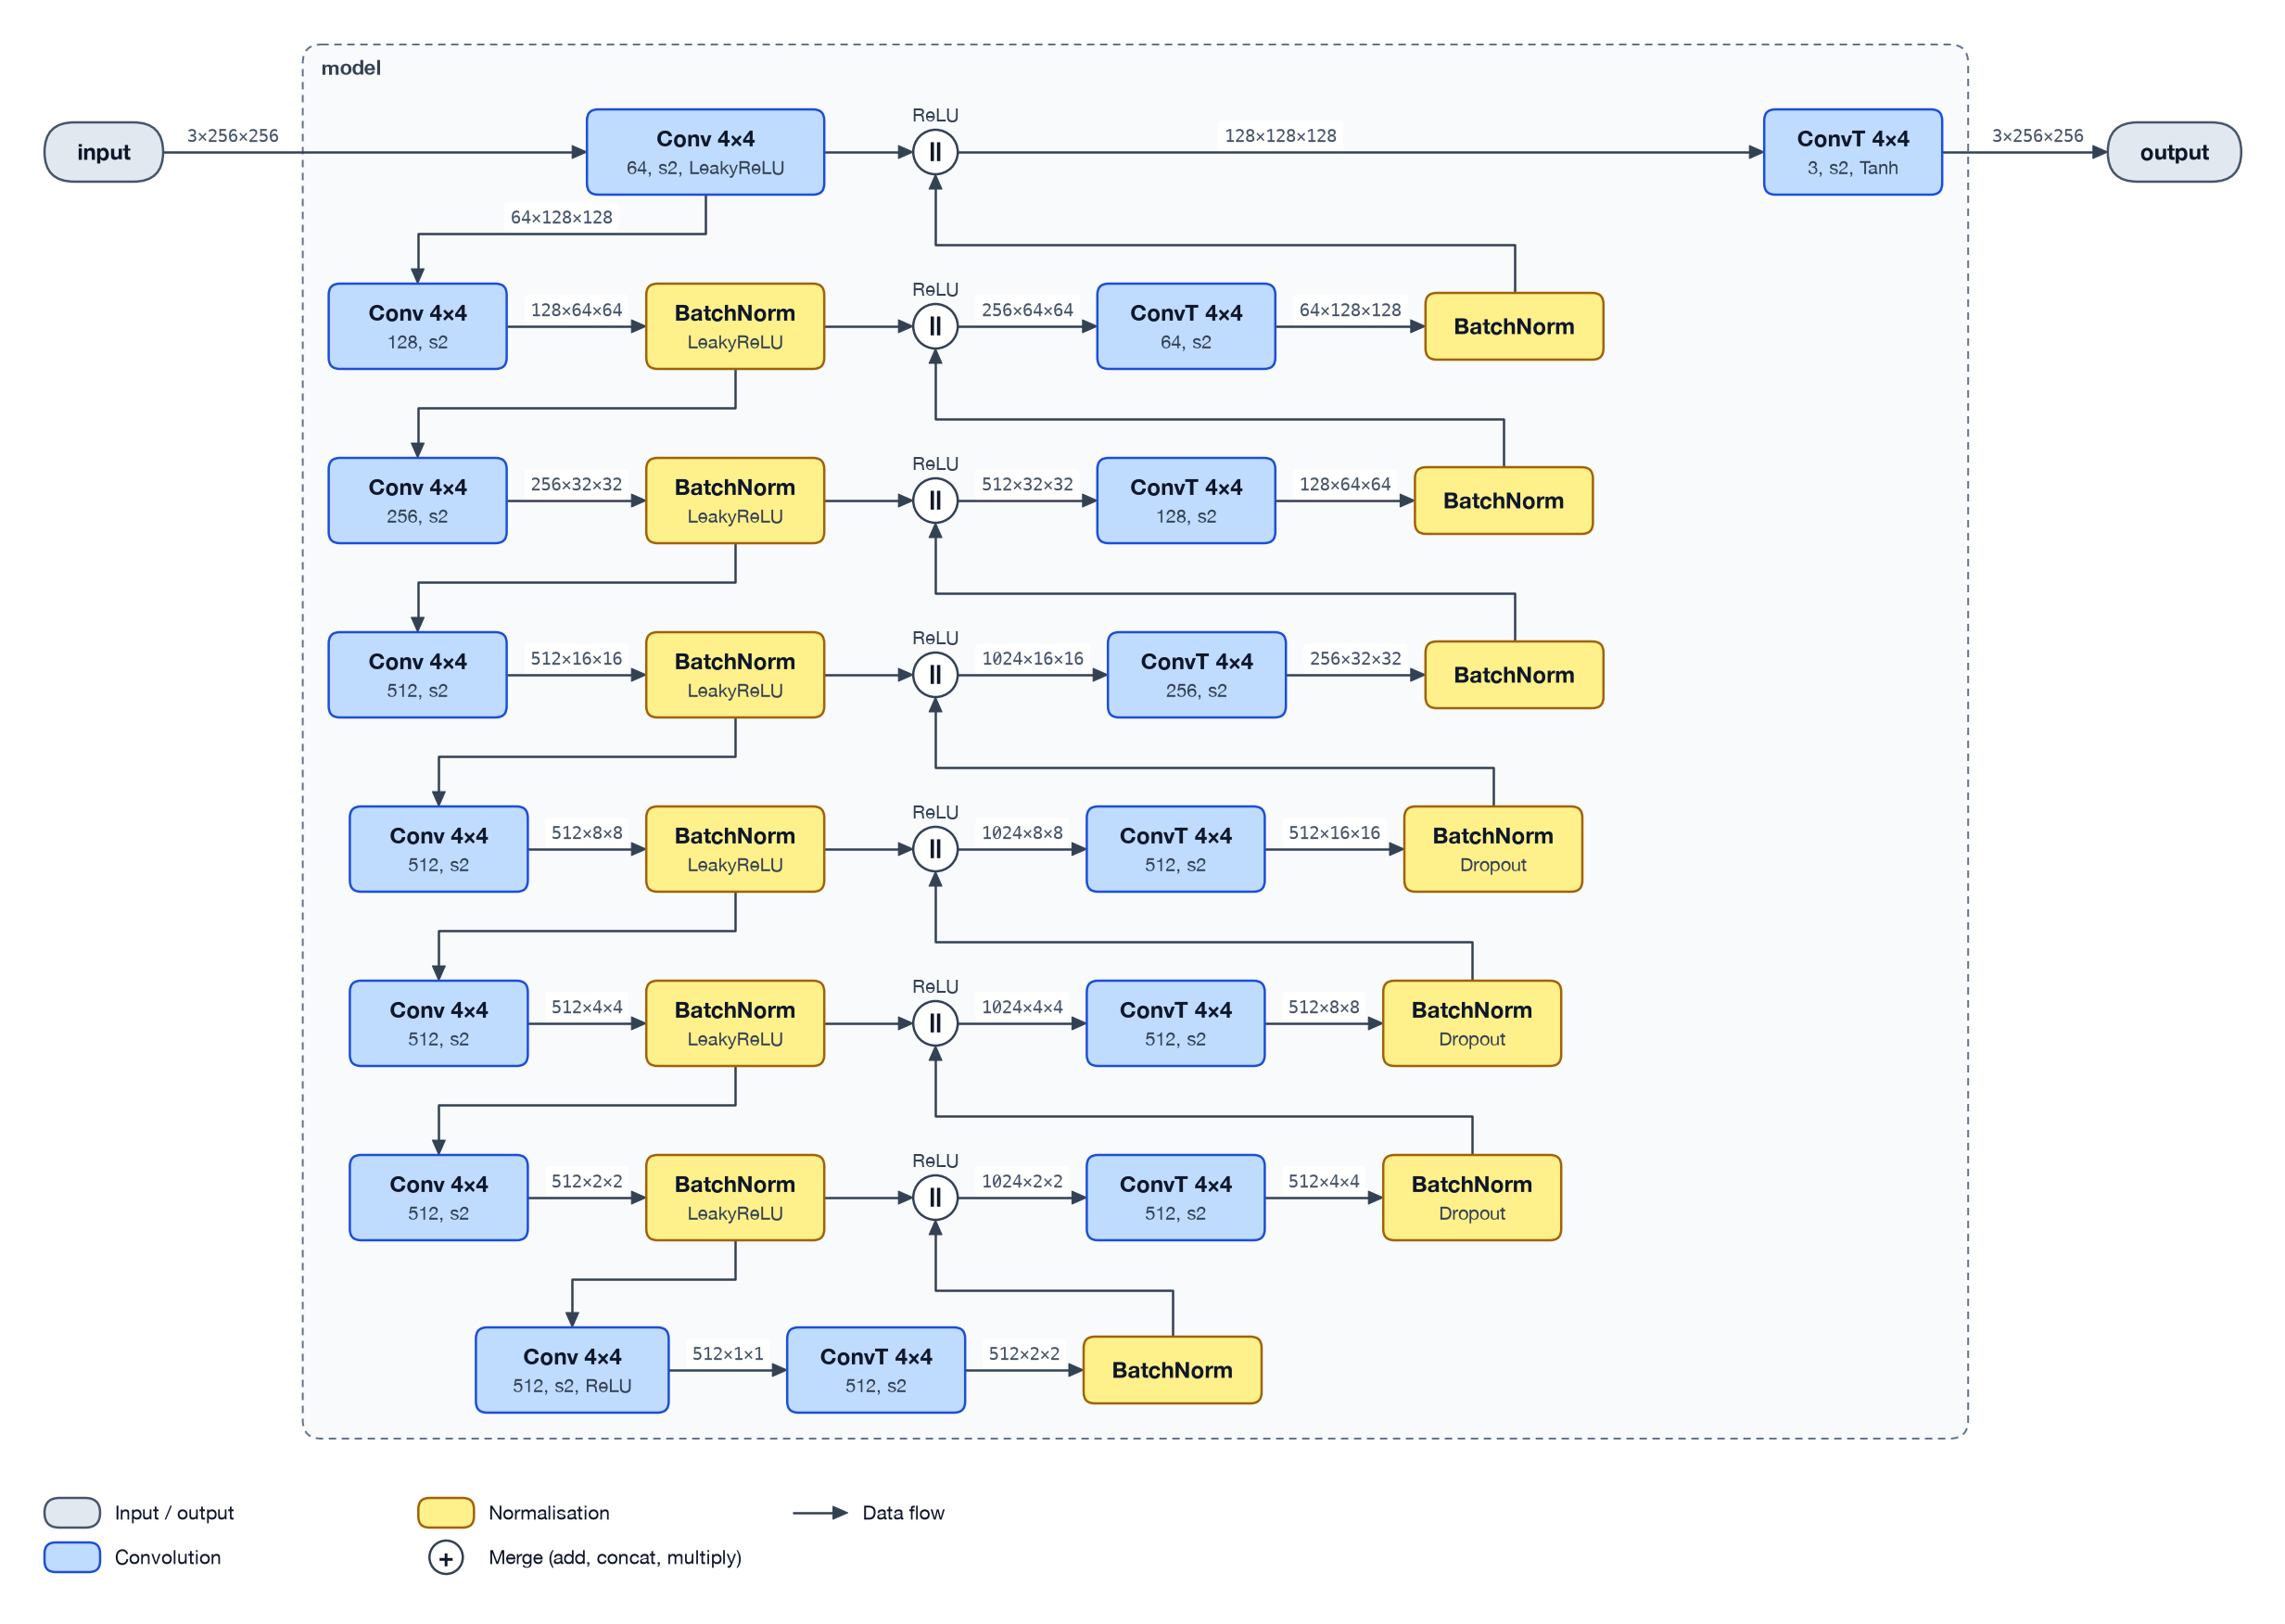

In [3]:
import tensorgami as tg

tg.draw(generator, x)

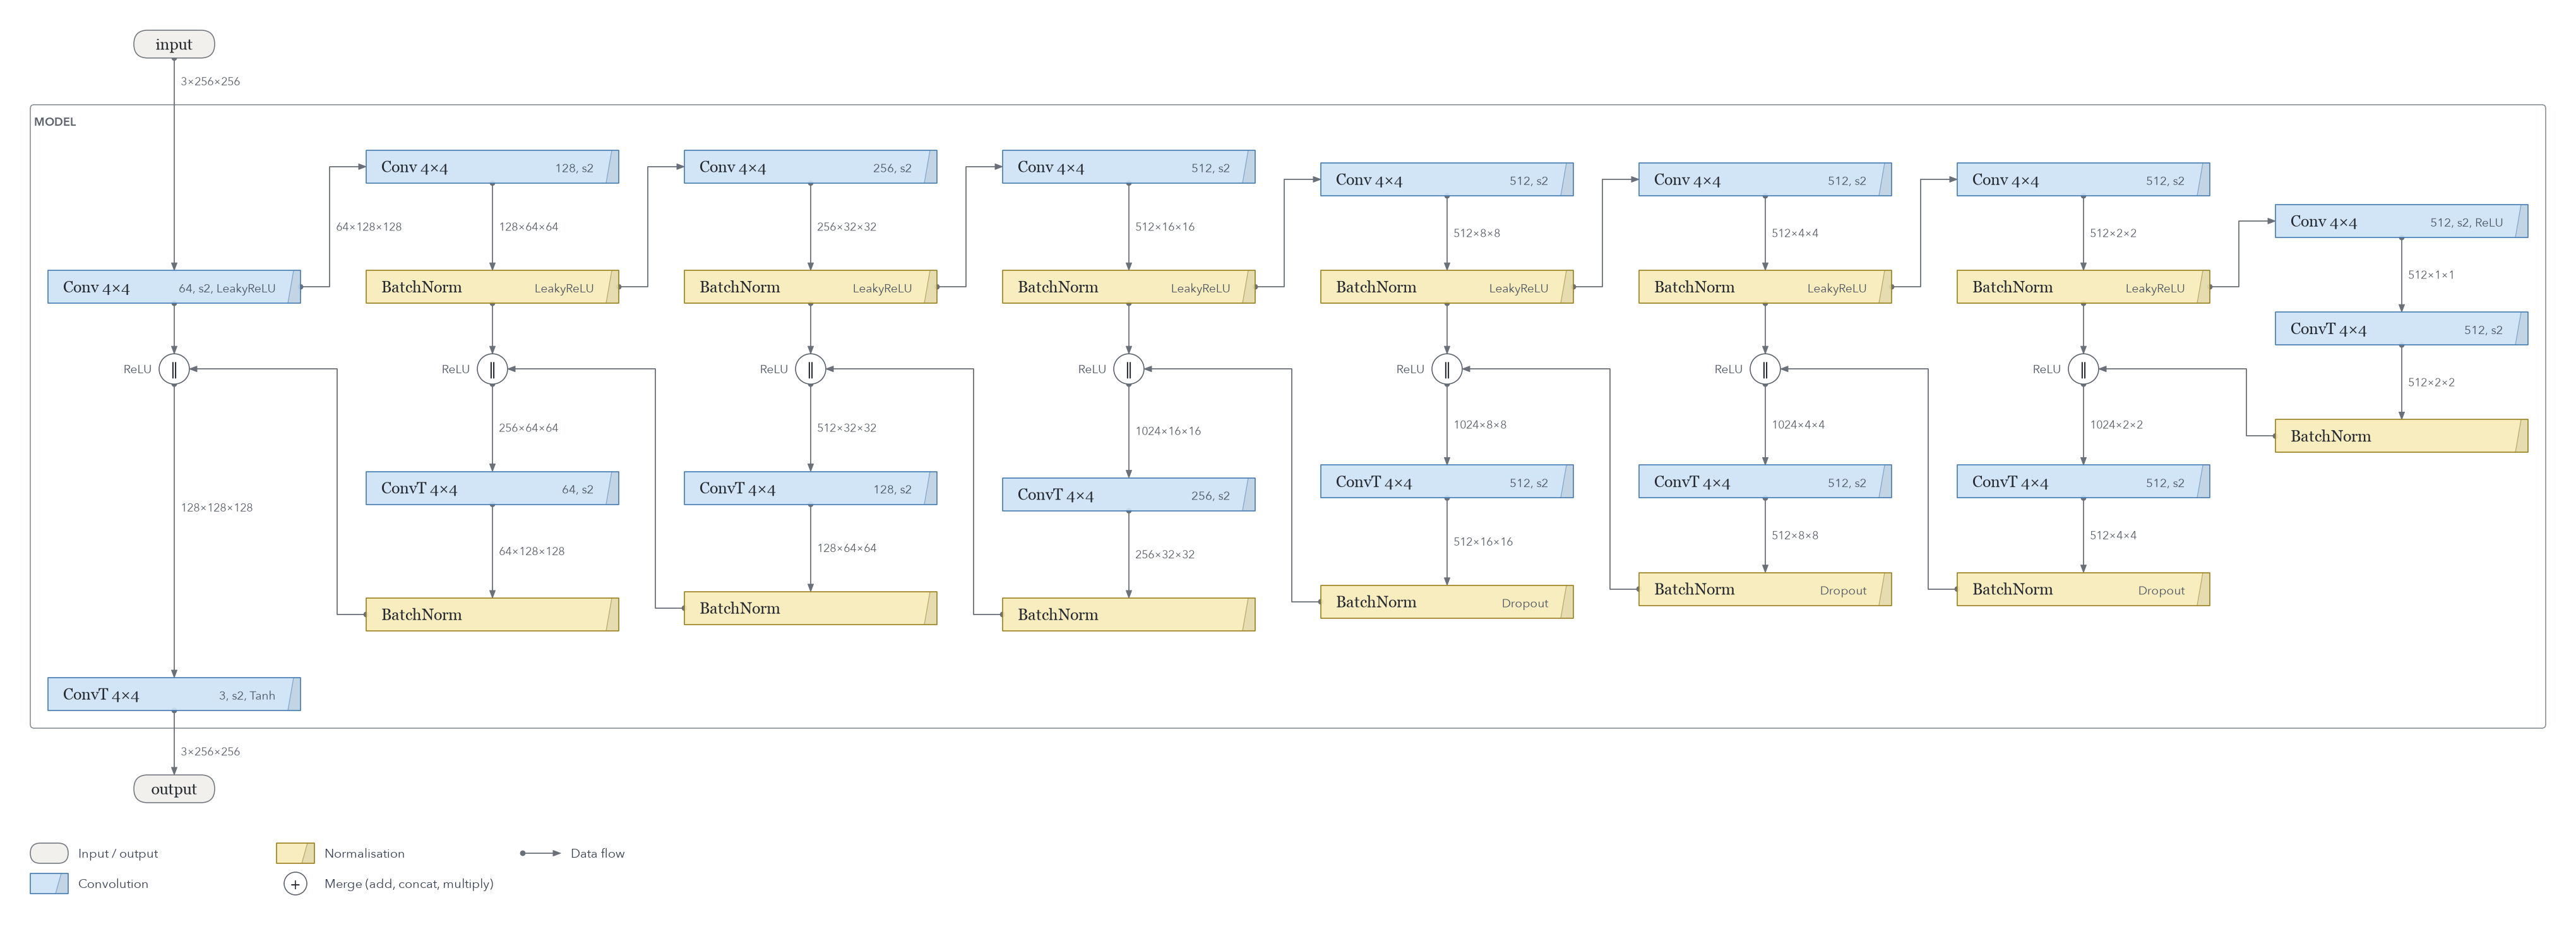

In [4]:
tg.draw(generator, x, style="origami-extended")  # levels become columns, top → bottom

`u_shape=False` keeps it on one line (about 8 000 px wide for 8 levels), and `level="stages"`
shows a single box, because the generator has one sub-module (`model`) holding all the rest.

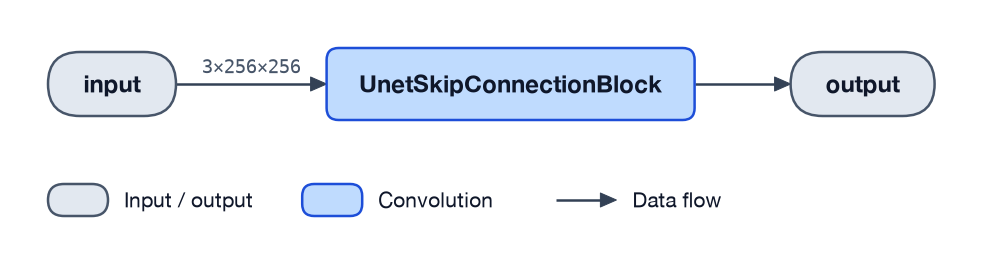

In [5]:
tg.draw(generator, x, level="stages")

### The discriminator: a PatchGAN

It sees the input and the output image stacked along the channels (3 + 3 = 6) and scores each
70 × 70 patch: a 30 × 30 map for a 256 × 256 image.

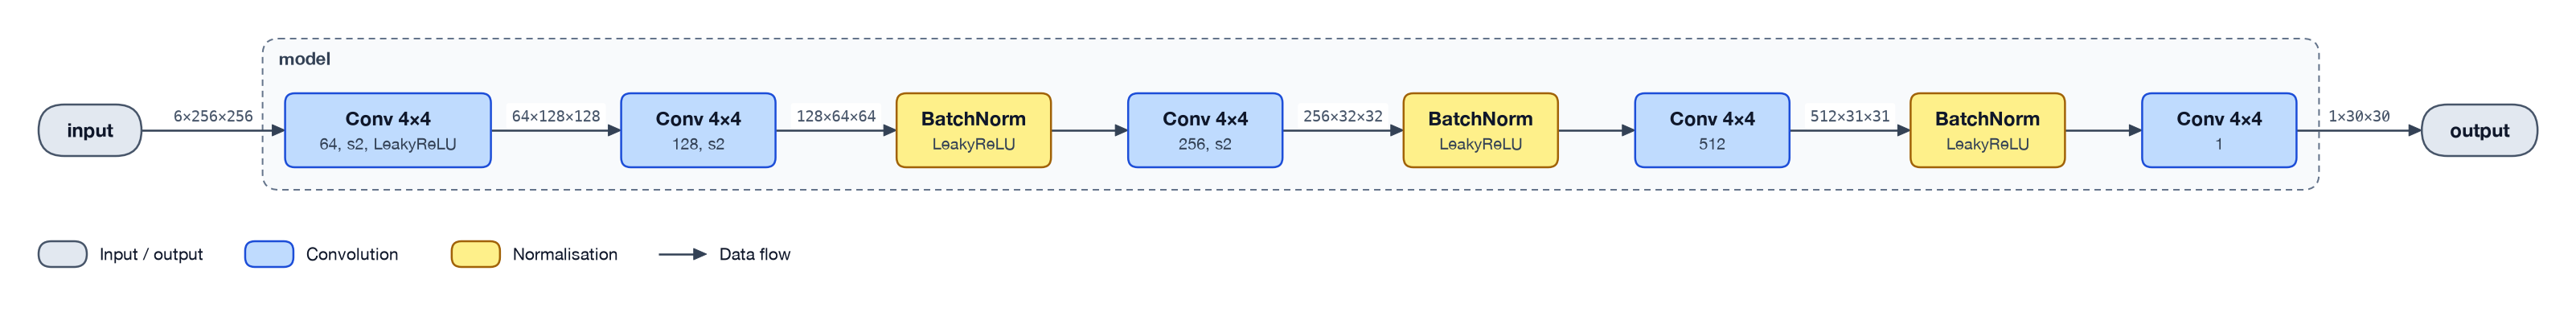

In [6]:
pair = torch.cat([x, y], 1)  # input A and (generated) output B, 6 channels

tg.draw(discriminator, pair)

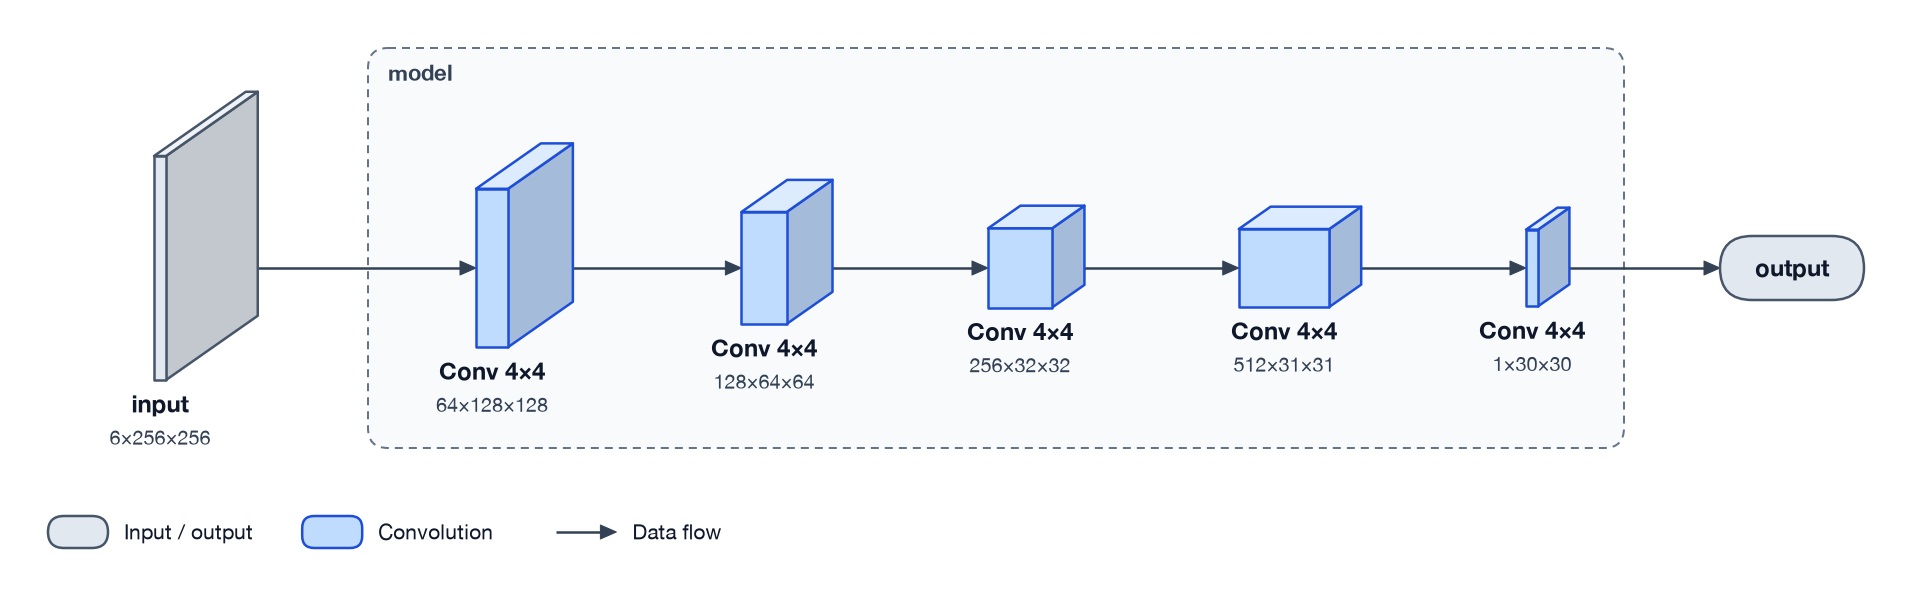

In [7]:
tg.draw(discriminator, pair, view="volume")  # the feature maps as volumes

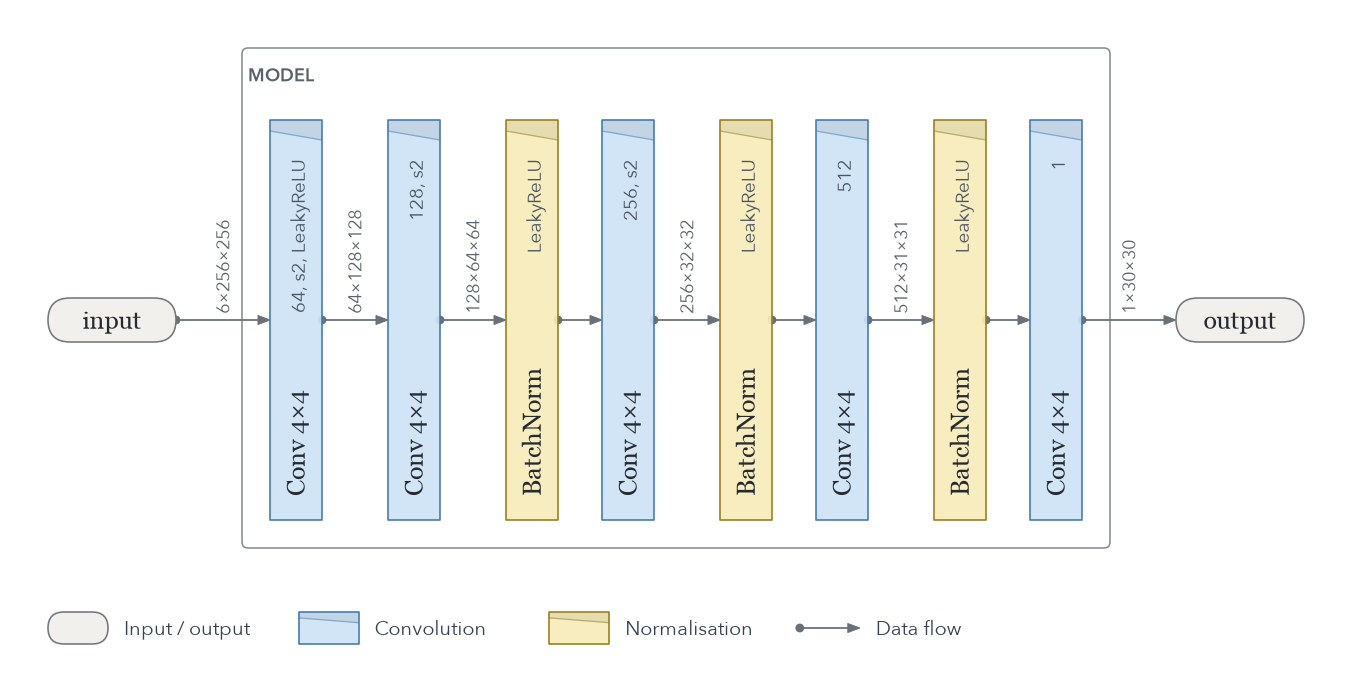

In [8]:
tg.draw(discriminator, pair, style="origami")

### Both networks in one matplotlib figure

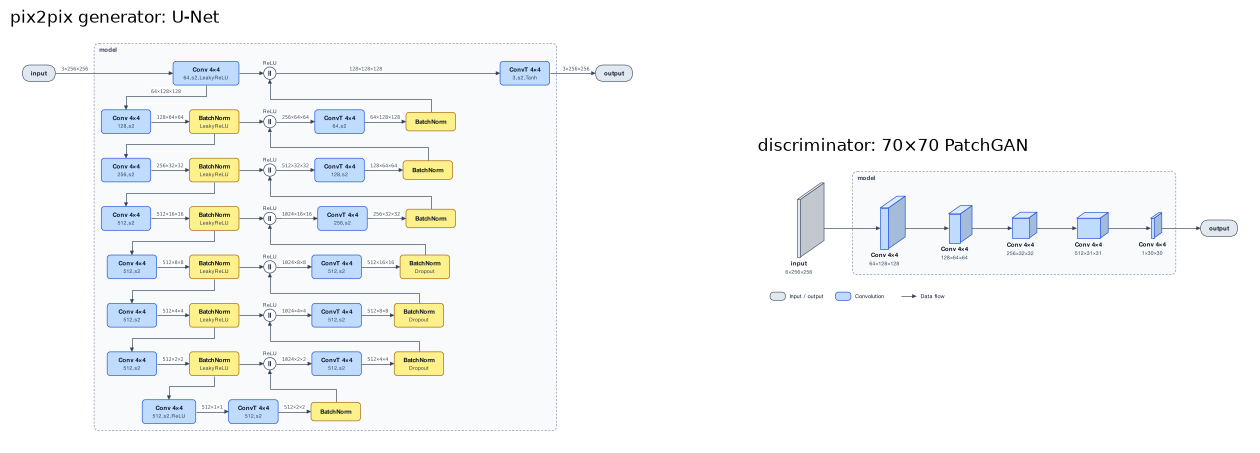

In [9]:
import matplotlib.pyplot as plt

g, d = tg.draw(generator, x, legend=False), tg.draw(discriminator, pair, view="volume")
panels, (left, right) = plt.subplots(1, 2, figsize=(16, 6), width_ratios=[g.size[0], d.size[0]])
g.draw_on(left)
d.draw_on(right)
left.set_title("pix2pix generator: U-Net", loc="left")
right.set_title("discriminator: 70×70 PatchGAN", loc="left")
plt.show()

## The whole pix2pix system in 3-D

Both networks in one figure, as they are trained: the input image A goes into the generator,
whose output (fake B) the discriminator judges together with A; the discriminator also judges
the real image B with A. The GAN loss trains both networks, the L1 loss between fake B and
real B the generator (λ = 100 in the paper): that is why two dashed arrows rise into the
generator, one from each loss, each labelled with its loss.

pix2pix's training code stacks A and B before calling the discriminator
(`netD(torch.cat((real_A, fake_B), 1))`); a small wrapper makes them two inputs, so the figure
shows where each comes from.

The generator has 8 levels; `u_levels=4` draws the first three and the innermost one,
with ⋮ for the levels in between, which keeps the figure compact (leave it out to draw
every level).

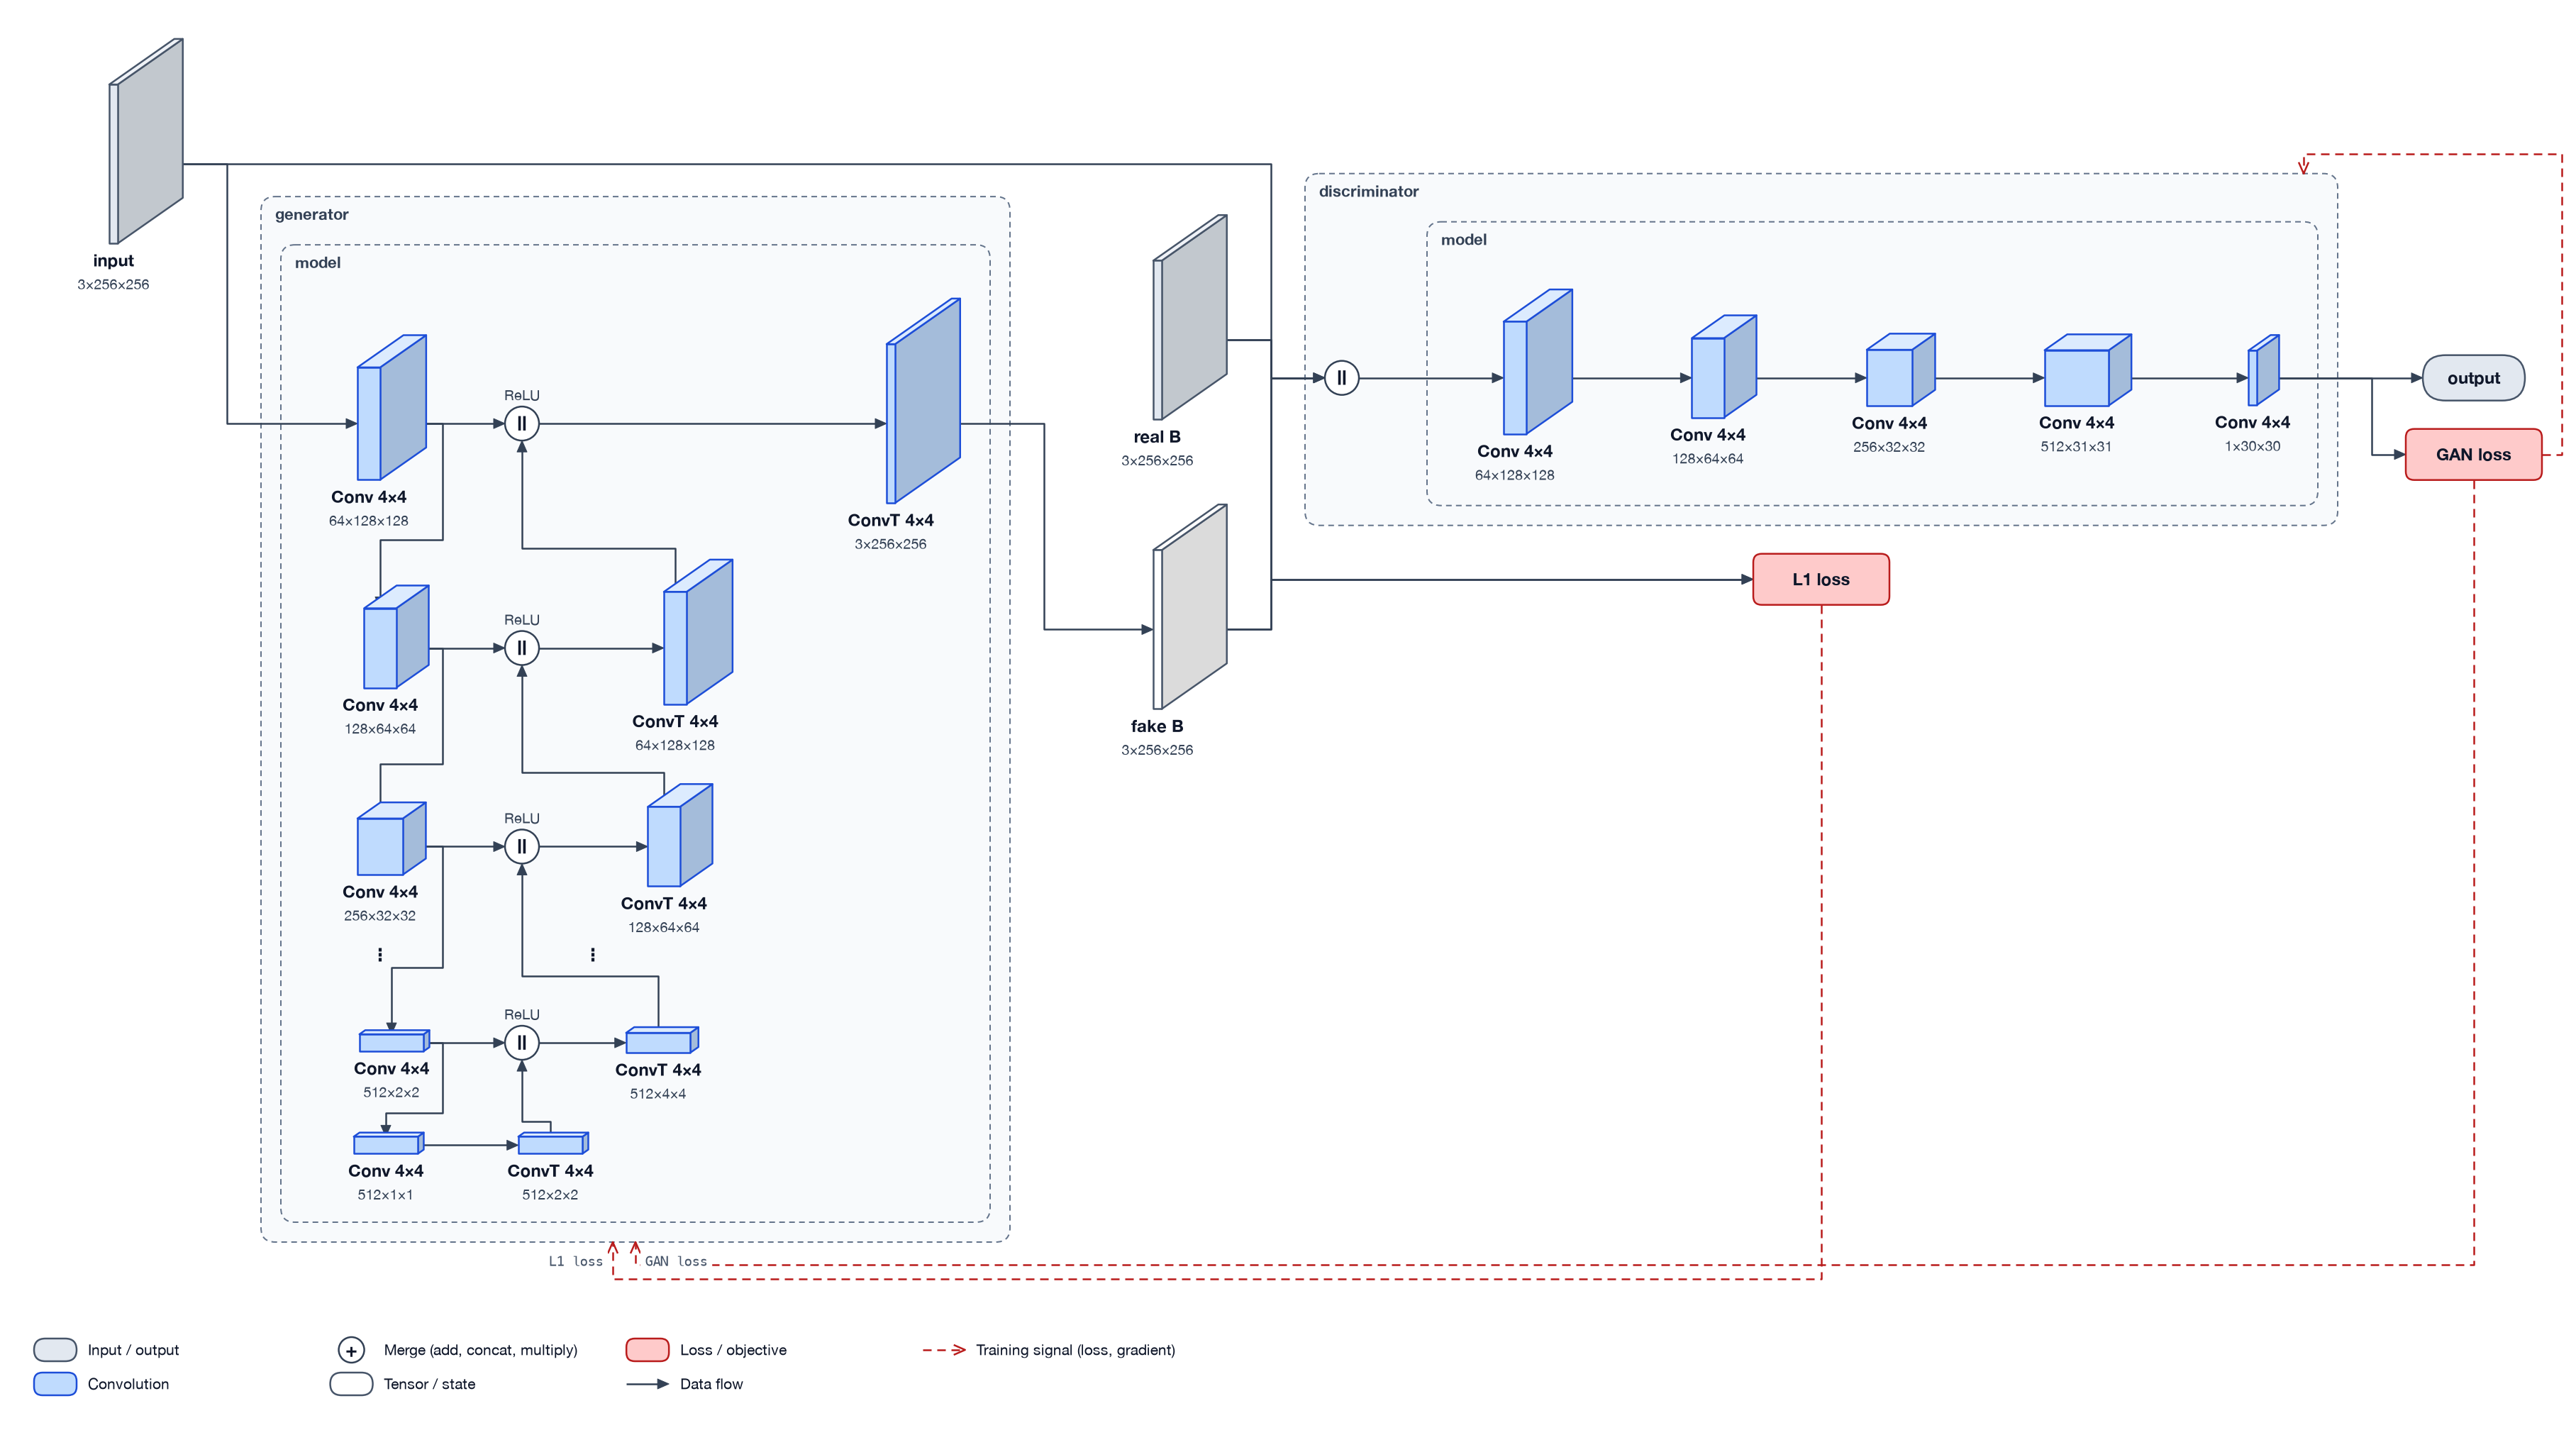

In [10]:
class ConditionalDiscriminator(nn.Module):
    """The PatchGAN judging an image B together with its input image A."""

    def __init__(self, netD):
        super().__init__()
        self.netD = netD

    def forward(self, A, B):
        return self.netD(torch.cat([A, B], 1))


models = {"generator": generator, "discriminator": ConditionalDiscriminator(discriminator)}
inputs = {"generator": x, "discriminator": {"A": x, "B": y}}
system = dict(
    links=[
        ("generator.input", "discriminator.A", "A"),  # the input image feeds both networks
        ("generator", "discriminator.B", "fake B"),  # the generator's output is judged
    ],
    annotations=[
        tg.Input("real B", to="discriminator.B"),  # … and so is the real image B
        tg.Loss("GAN loss", "discriminator", trains=["generator", "discriminator"]),
        tg.Loss("L1 loss", "generator", "real B", trains=["generator"]),
    ],
)

tg.draw(models, inputs, view="volume", u_levels=4, **system)

The same system at `level=0`: each network one box.

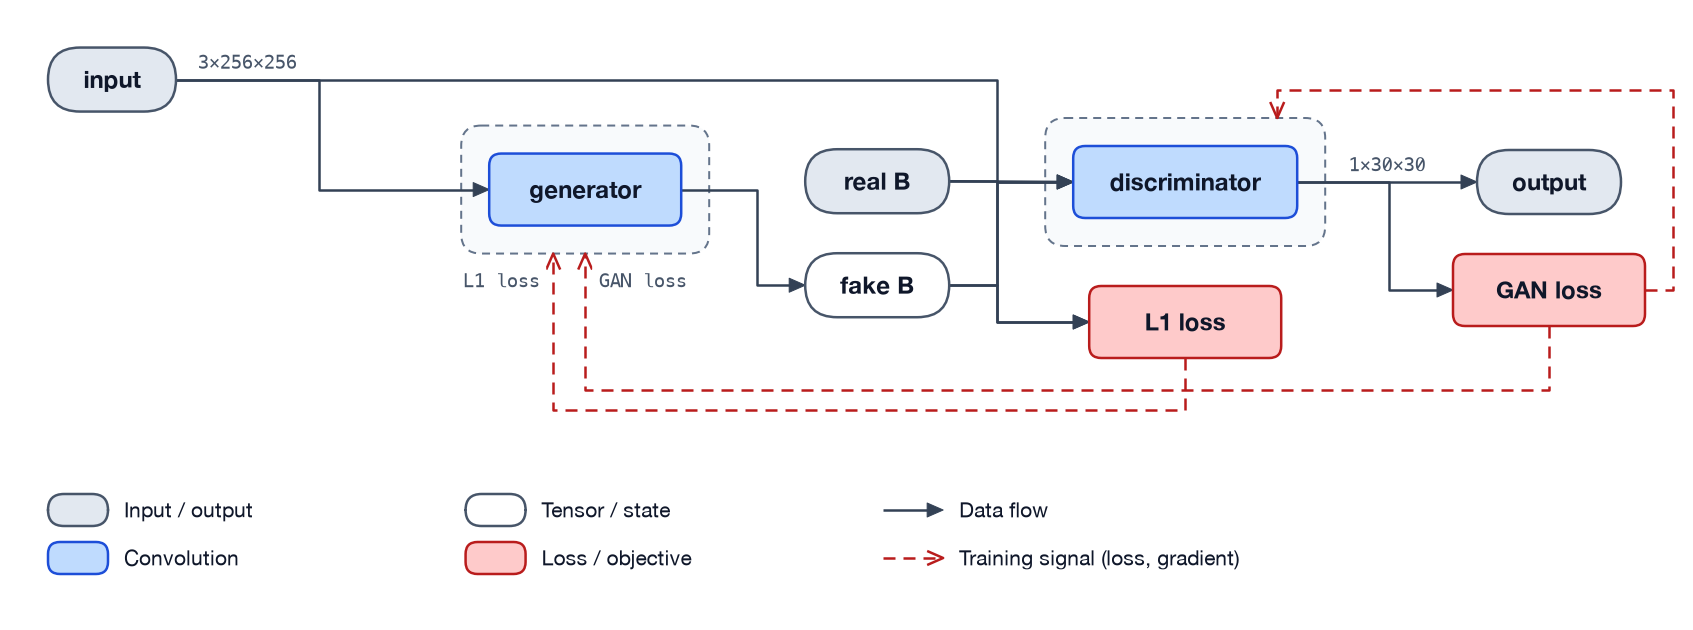

In [11]:
tg.draw(models, inputs, level=0, **system)